# Assignment 2: training pipeline


# Assignment 2: olive peacock spot detection on olive leaves

This notebook is the full training pipeline. It runs start to finish with
`uv run python main.py train`, with no manual steps, and does the following:

1. **Downloads the dataset** from Roboflow Universe (`project-9k7w7/olive1-ngwty`, v1):
   olive leaves in three classes (healthy, Aculus olearius and peacock spot).
2. **Describes the dataset**: images per class and per split, plus visual examples
   to check whether the test set resembles what the technician would see in the field.
3. **Finetunes `yolo11n-cls`** starting from the pretrained checkpoint.
4. **Evaluates it on the test split** against two baselines (the pretrained model
   without finetuning, and one that always predicts the majority class), with
   per-class results.
5. **Costs each threshold**: a missed peacock spot costs ~€400/ha and an unnecessary
   treatment ~€110/ha, with a 25% base rate.
6. **Saves to `weights/` and `results/`** everything the app needs, so the dashboard
   never has to train anything.

In [1]:
from pathlib import Path
import random

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from roboflow import Roboflow

from api_key import load_api_key


ROOT = Path.cwd()
DATA_DIR = ROOT / "datasets" / "olive1-v1"   
RESULTS_DIR = ROOT / "results"               
WEIGHTS_DIR = ROOT / "weights"               
RESULTS_DIR.mkdir(exist_ok=True)
WEIGHTS_DIR.mkdir(exist_ok=True)


WORKSPACE = "project-9k7w7"
PROJECT = "olive1-ngwty"
VERSION = 1

SEED = 42
random.seed(SEED)

In [2]:
if not (DATA_DIR / "train").exists():
    rf = Roboflow(api_key=load_api_key())
    version = rf.workspace(WORKSPACE).project(PROJECT).version(VERSION)
    version.download("folder", location=str(DATA_DIR))
else:
    print("Dataset ya descargado en", DATA_DIR)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /Users/joseluishervasdecela_1/Desktop/daiist-assignment-2/datasets/olive1-v1 in folder:: 100%|██████████| 8727/8727 [00:00<00:00, 8945.71it/s]


In [3]:
valid_dir = DATA_DIR / "valid"
if valid_dir.exists() and not (DATA_DIR / "val").exists():
    valid_dir.rename(DATA_DIR / "val")

print(sorted(p.name for p in DATA_DIR.iterdir()))

['README.dataset.txt', 'README.roboflow.txt', 'test', 'train', 'val']


In [4]:
IMG_EXT = {".jpg", ".jpeg", ".png"}
SPLITS = ["train", "val", "test"]

def list_images(folder):
    return [f for f in folder.iterdir() if f.suffix.lower() in IMG_EXT]

def original_id(file):
    # Roboflow names files like "524_jpg.rf.<hash>.jpg". Augmented copies of the
    # same photo share the part before ".rf.", so that part identifies the original.
    return file.name.split(".rf.")[0]

rows = []
for split in SPLITS:
    for class_dir in sorted(p for p in (DATA_DIR / split).iterdir() if p.is_dir()):
        files = list_images(class_dir)
        rows.append({
            "split": split,
            "class": class_dir.name,
            "files": len(files),                                # includes augmented copies
            "originals": len({original_id(f) for f in files}),  # real, distinct photos
        })

counts = pd.DataFrame(rows)
counts.to_csv(RESULTS_DIR / "dataset_counts.csv", index=False)

print("Files on disk (train includes augmented copies):")
print(counts.pivot(index="class", columns="split", values="files")[SPLITS].to_string())
print("\nDistinct original photos:")
print(counts.pivot(index="class", columns="split", values="originals")[SPLITS].to_string())

Files on disk (train includes augmented copies):
split               train  val  test
class                               
Healthy              2268   49    86
aculus_olearius      2238   42    88
olive_peacock_spot   3726   67   149

Distinct original photos:
split               train  val  test
class                               
Healthy               756   49    86
aculus_olearius       746   42    88
olive_peacock_spot   1242   67   149


In [5]:
# Leakage check: the same original photo should never appear in two splits.
# If it did, the model would be tested on photos it already saw in training.
def ids_in_split(split):
    return {f"{f.parent.name}/{original_id(f)}"
            for f in (DATA_DIR / split).rglob("*") if f.suffix.lower() in IMG_EXT}

ids = {s: ids_in_split(s) for s in SPLITS}
print("train & val :", len(ids["train"] & ids["val"]))
print("train & test:", len(ids["train"] & ids["test"]))
print("val & test  :", len(ids["val"] & ids["test"]))

# Image size after Roboflow preprocessing (expected 224x224, stretched)
sample = list_images(DATA_DIR / "test" / counts["class"].iloc[0])[0]
print("\nImage size:", Image.open(sample).size)

train & val : 0
train & test: 0
val & test  : 0

Image size: (224, 224)


Healthy: ['A319_jpg', 'A442_jpg', 'A593_jpg', 'A697_JPG']
aculus_olearius: ['103_jpg', '133_jpg', '136_jpg', '154_jpg']
olive_peacock_spot: ['A140_jpg', 'A271_jpg', 'A302_jpg', 'A344_jpg']


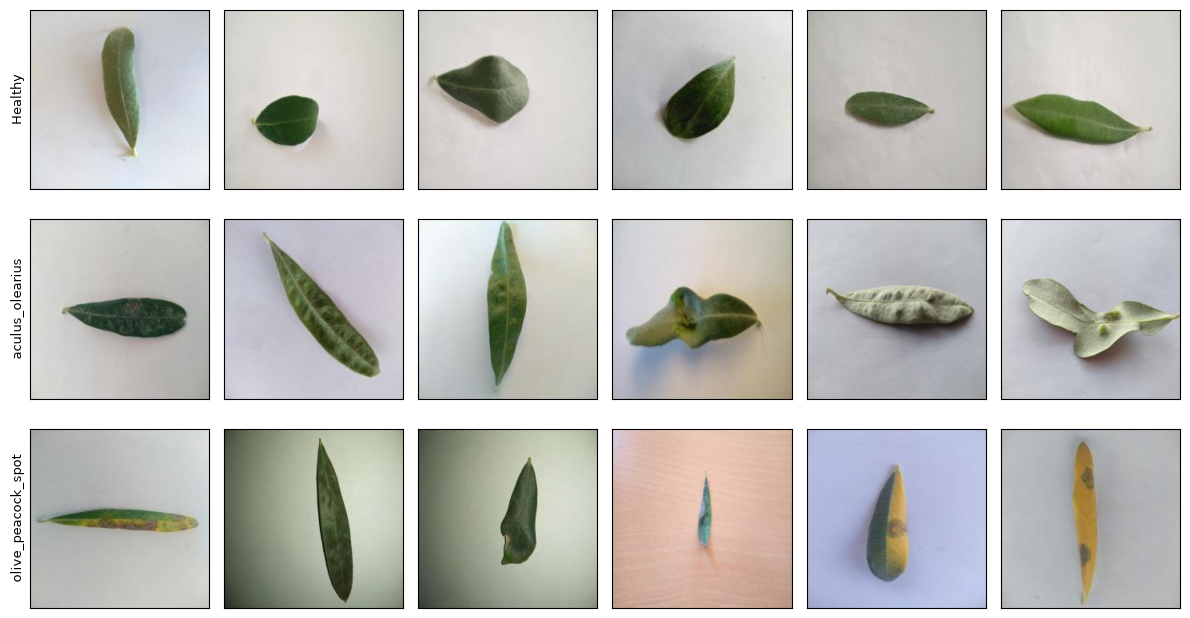

In [6]:
# Show 6 random test images per class and the first filenames of each class.
# Purpose: check whether classes differ in background or source (camera, naming),
# which the model could learn instead of the disease.
classes = sorted(p.name for p in (DATA_DIR / "test").iterdir() if p.is_dir())
n_cols = 6
fig, axes = plt.subplots(len(classes), n_cols, figsize=(2 * n_cols, 2.2 * len(classes)))
for r, cls in enumerate(classes):
    files = sorted(list_images(DATA_DIR / "test" / cls))
    for c, f in enumerate(random.sample(files, n_cols)):
        ax = axes[r, c]
        ax.imshow(Image.open(f))
        ax.set_xticks([]); ax.set_yticks([])
        if c == 0:
            ax.set_ylabel(cls, fontsize=9)
    print(f"{cls}: {[original_id(f) for f in files[:4]]}")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "test_samples.png", dpi=120)